#Business Understanding

project tilte

In [ ]:
# ============================================================
# CUSTOMER CHURN PREDICTION AND ANALYTICS
# Data Science Project
# ============================================================

PROJECT_NAME = "Retail Customer Churn Prediction and Analytics"

print(PROJECT_NAME)
print("=" * 60)

Retail Customer Churn Prediction and Analytics


##Business problem

In [ ]:
business_problem = """
A retail company wants to understand why customers leave and
identify customers who are at higher risk of churn.

The objective is to analyze customer behavior, identify factors
associated with churn, develop predictive classification models,
compare multiple models, and select the best reliable model
for future churn prediction.
"""

print(business_problem)


A retail company wants to understand why customers leave and
identify customers who are at higher risk of churn.

The objective is to analyze customer behavior, identify factors
associated with churn, develop predictive classification models,
compare multiple models, and select the best reliable model
for future churn prediction.



##Project objectives

In [ ]:
objectives = [
    "Understand customer characteristics and churn behavior",
    "Identify data quality issues",
    "Perform exploratory data analysis",
    "Identify factors associated with customer churn",
    "Prepare data for machine learning",
    "Train and compare five classification models",
    "Select the best model using suitable evaluation metrics",
    "Explain the important drivers of churn",
    "Save the final model for deployment"
]

for i, objective in enumerate(objectives, 1):
    print(f"{i}. {objective}")

1. Understand customer characteristics and churn behavior
2. Identify data quality issues
3. Perform exploratory data analysis
4. Identify factors associated with customer churn
5. Prepare data for machine learning
6. Train and compare five classification models
7. Select the best model using suitable evaluation metrics
8. Explain the important drivers of churn
9. Save the final model for deployment


#Data collection

import libraries

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Model saving
import joblib

# Utilities
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


Upload dataset to colab

In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving retail_customer_churn_100k (1).csv to retail_customer_churn_100k (1).csv
Uploaded files:
retail_customer_churn_100k (1).csv


Load dataset

In [ ]:
import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Dataset loaded successfully.
Rows    : 100,000
Columns : 18


#Data Understanding

##First records

In [ ]:
df.head()

,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
0,C000001,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,Medium,1
1,C000002,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,Medium,1
2,C000003,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,High,1
3,C000004,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,Low,0
4,C000005,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,High,1


##Last records

In [ ]:
df.tail()

,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
99995,C099996,25-34,Male,Central,Loyal,In-Store,8,363.84,2596.84,191,54,0.72,0.10,0.30,67,40.0,Low,0
99996,C099997,25-34,Other,West,New,In-Store,2,195.94,337.17,104,5,0.59,0.05,0.28,51,38.5,Low,0
99997,C099998,18-24,Male,Central,Loyal,Mobile App,2,40.53,93.39,150,11,0.44,0.63,0.31,59,66.0,Low,0
99998,C099999,25-34,Male,Central,VIP,Online,12,173.99,2476.75,201,70,0.70,0.39,0.67,72,36.0,Medium,0
99999,C100000,35-44,Female,Central,Loyal,In-Store,8,223.49,1758.39,321,61,0.76,0.44,0.14,47,65.0,High,1


##Dataset dimentions

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 100000
Number of columns: 18


##Column names

In [ ]:
for i, column in enumerate(df.columns, 1):
    print(f"{i:02d}. {column}")

01. customer_id
02. age_group
03. gender
04. region
05. customer_segment
06. preferred_channel
07. purchase_frequency
08. avg_order_value
09. total_spent
10. recency_days
11. website_visits
12. discount_usage_rate
13. email_open_rate
14. cart_abandonment_rate
15. loyalty_score
16. engagement_score
17. churn_risk
18. churn_flag


##Data types

In [ ]:
df.dtypes

,0
customer_id,object
age_group,object
gender,object
region,object
customer_segment,object
preferred_channel,object
purchase_frequency,int64
avg_order_value,float64
total_spent,float64
recency_days,int64


##Dataset information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   customer_id            100000 non-null  object 
 1   age_group              100000 non-null  object 
 2   gender                 100000 non-null  object 
 3   region                 100000 non-null  object 
 4   customer_segment       100000 non-null  object 
 5   preferred_channel      100000 non-null  object 
 6   purchase_frequency     100000 non-null  int64  
 7   avg_order_value        100000 non-null  float64
 8   total_spent            100000 non-null  float64
 9   recency_days           100000 non-null  int64  
 10  website_visits         100000 non-null  int64  
 11  discount_usage_rate    100000 non-null  float64
 12  email_open_rate        100000 non-null  float64
 13  cart_abandonment_rate  100000 non-null  float64
 14  loyalty_score          100000 non-nul

# Data Quality

##Mising values

In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing_Count",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
customer_id,0,0.0
age_group,0,0.0
gender,0,0.0
region,0,0.0
customer_segment,0,0.0
preferred_channel,0,0.0
purchase_frequency,0,0.0
avg_order_value,0,0.0
total_spent,0,0.0
recency_days,0,0.0


##Duplicate rows

In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


##Duplicate customer IDs

In [ ]:
duplicate_customer_ids = df["customer_id"].duplicated().sum()

print("Duplicate customer IDs:", duplicate_customer_ids)

Duplicate customer IDs: 0


##Uniqe values

In [ ]:
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [df[col].nunique() for col in df.columns]
})

unique_summary

,Column,Unique Values
0,customer_id,100000
1,age_group,5
2,gender,3
3,region,5
4,customer_segment,4
5,preferred_channel,3
6,purchase_frequency,9
7,avg_order_value,35250
8,total_spent,86590
9,recency_days,364


##Categorical values

In [ ]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print("\n" + "=" * 50)
    print(column)
    print(df[column].value_counts())


customer_id
customer_id
C099984    1
C099983    1
C099982    1
C099981    1
C099980    1
          ..
C000005    1
C000004    1
C000003    1
C000002    1
C000001    1
Name: count, Length: 100000, dtype: int64

age_group
age_group
35-44    20109
45-54    20093
18-24    19987
25-34    19929
55+      19882
Name: count, dtype: int64

gender
gender
Male      33434
Female    33367
Other     33199
Name: count, dtype: int64

region
region
East       20240
West       20039
North      20035
Central    20012
South      19674
Name: count, dtype: int64

customer_segment
customer_segment
New          25113
Returning    25106
VIP          24906
Loyal        24875
Name: count, dtype: int64

preferred_channel
preferred_channel
Online        33430
In-Store      33303
Mobile App    33267
Name: count, dtype: int64

churn_risk
churn_risk
Low       40141
High      32410
Medium    27449
Name: count, dtype: int64


#Target Analysis

##Churn distribution

In [ ]:
print(df["churn_flag"].value_counts())

print("\nPercentage:")
print(
    df["churn_flag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_flag
0    53776
1    46224
Name: count, dtype: int64

Percentage:
churn_flag
0    53.78
1    46.22
Name: proportion, dtype: float64


##Churn visualization

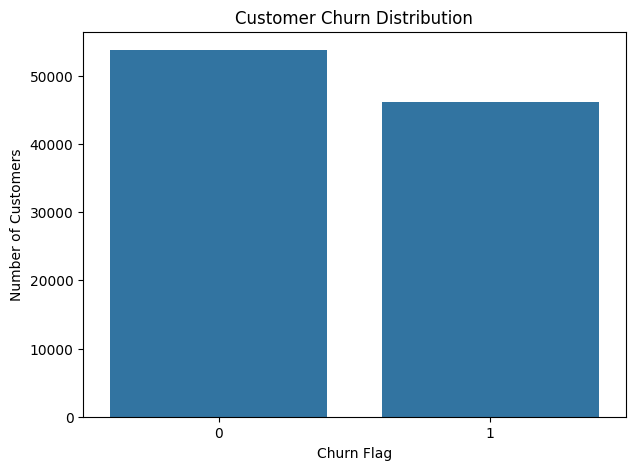

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="churn_flag"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Flag")
plt.ylabel("Number of Customers")

plt.show()

#Data Leakage Check

##Investigate Churn risk

In [ ]:
risk_churn = pd.crosstab(
    df["churn_risk"],
    df["churn_flag"],
    normalize="index"
) * 100

risk_churn.round(2)

churn_flag,0,1
churn_risk,,
High,0.00,100.00
Low,100.00,0.00
Medium,49.67,50.33


##Visualize leakage

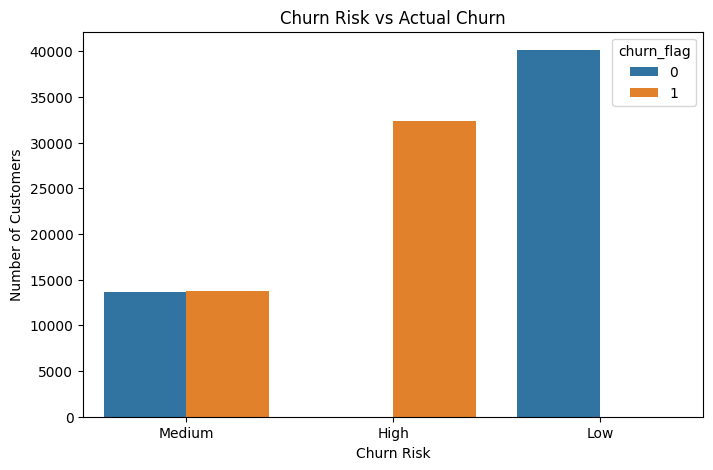

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="churn_risk",
    hue="churn_flag"
)

plt.title("Churn Risk vs Actual Churn")
plt.xlabel("Churn Risk")
plt.ylabel("Number of Customers")

plt.show()

Explain leakage

In [ ]:
print("""
DATA LEAKAGE DECISION
---------------------

The feature 'churn_risk' will NOT be used for machine learning.

Reason:
It has an almost direct relationship with the target 'churn_flag'.
Using it would allow the model to indirectly see the answer.

Therefore:
    churn_risk → excluded from predictive features

This produces a more realistic and defensible machine learning model.
""")


DATA LEAKAGE DECISION
---------------------

The feature 'churn_risk' will NOT be used for machine learning.

Reason:
It has an almost direct relationship with the target 'churn_flag'.
Using it would allow the model to indirectly see the answer.

Therefore:
    churn_risk → excluded from predictive features

This produces a more realistic and defensible machine learning model.



#EDA

#Numarical columns

In [ ]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print(numerical_columns)

['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score', 'churn_flag']


##Numerical distribution

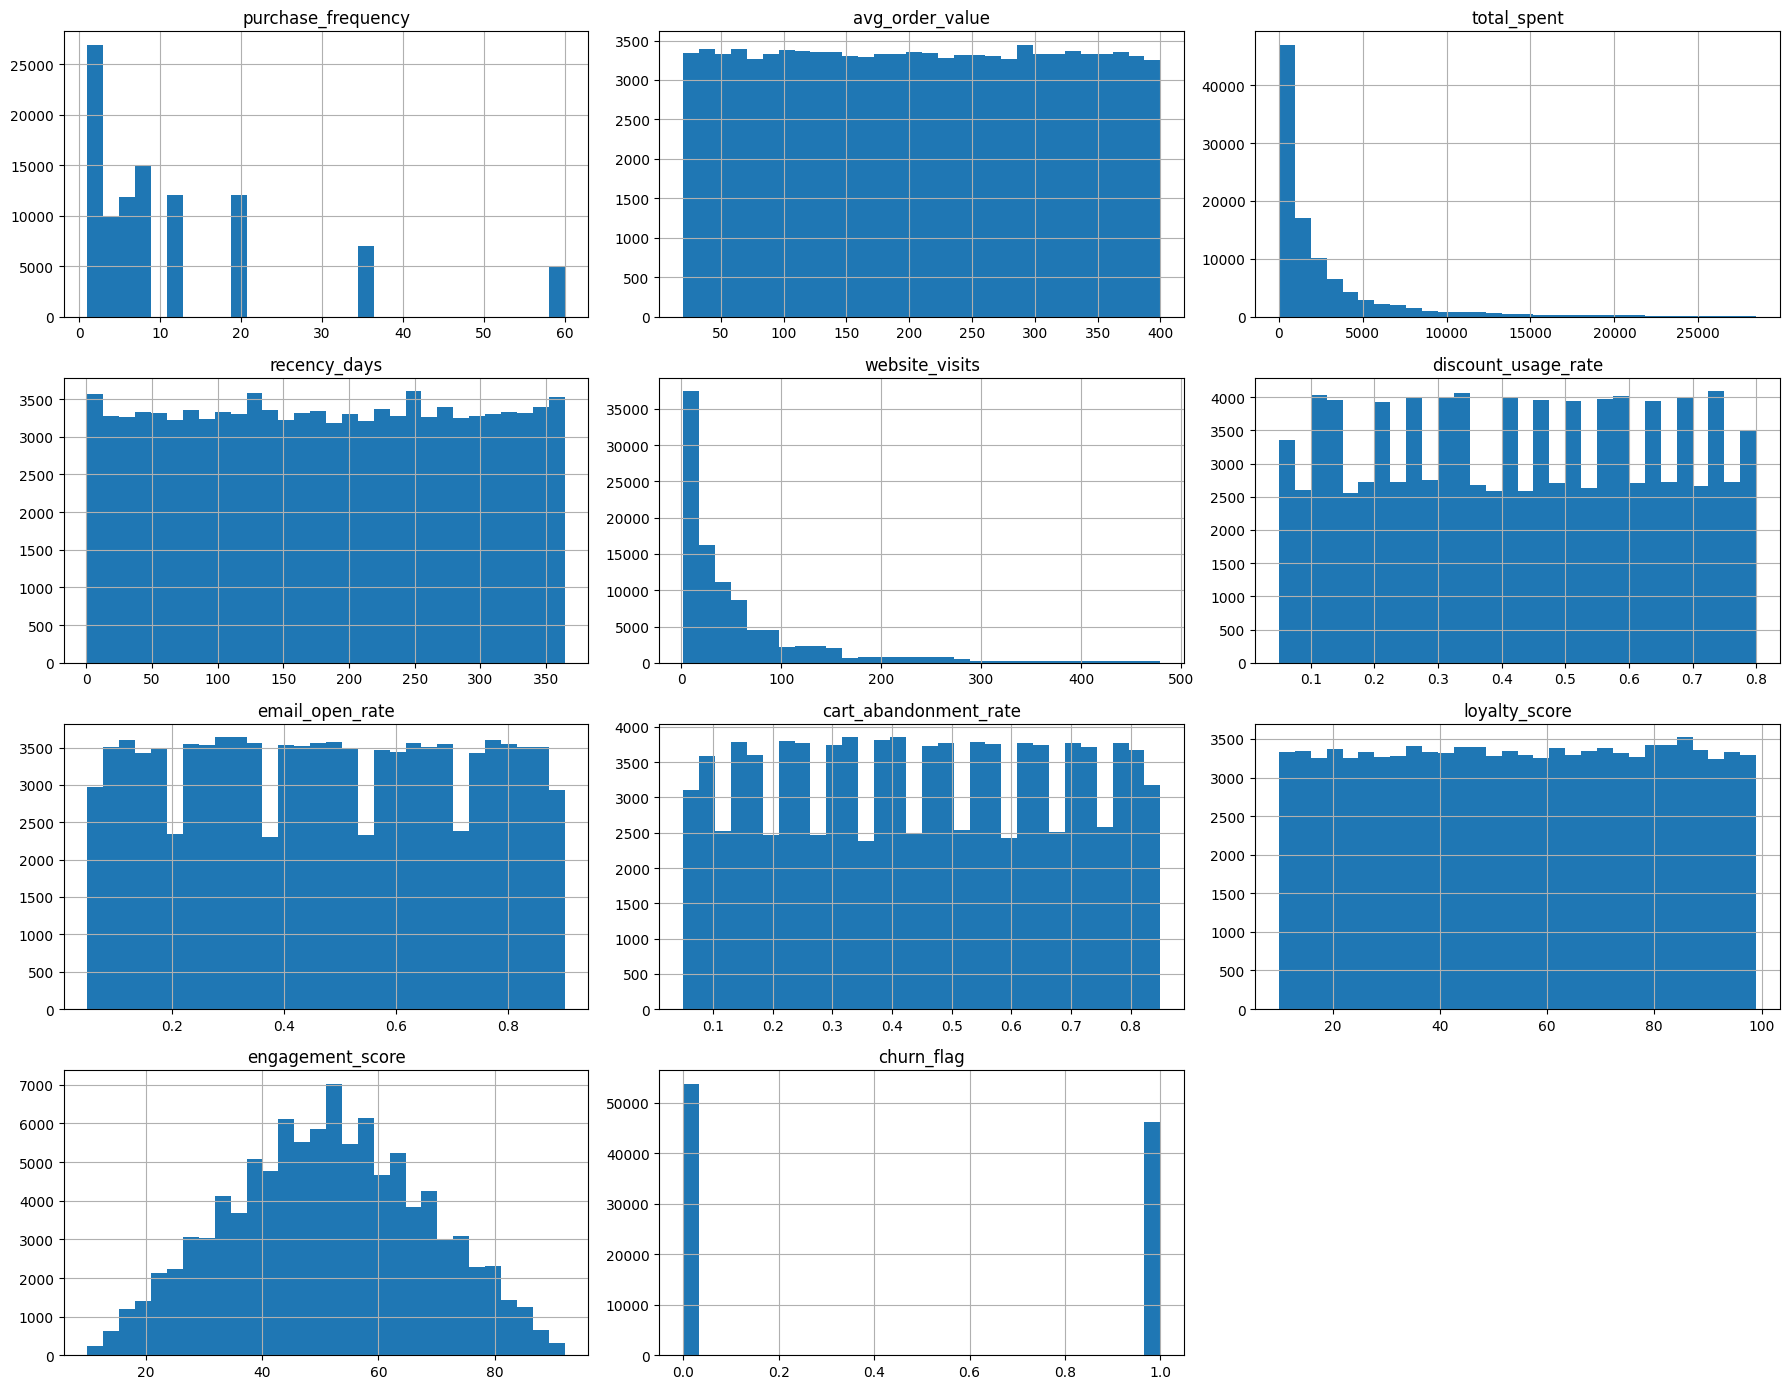

In [ ]:
df[numerical_columns].hist(
    figsize=(18, 14),
    bins=30
)

plt.tight_layout()
plt.show()

##Chuurn vs recency

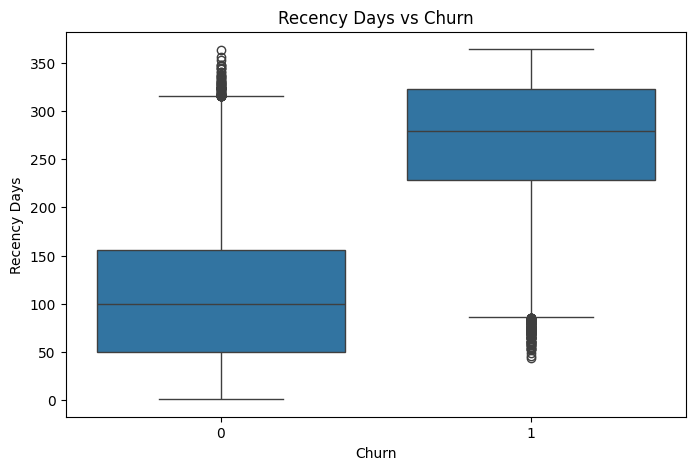

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="recency_days"
)

plt.title("Recency Days vs Churn")
plt.xlabel("Churn")
plt.ylabel("Recency Days")

plt.show()

#Churn vs purchase frequency

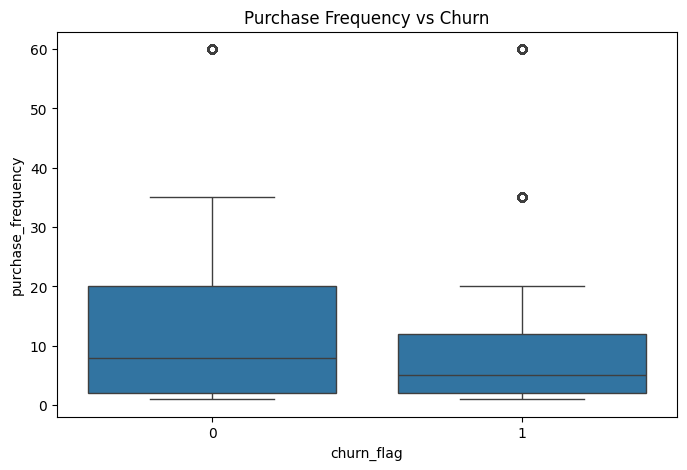

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="purchase_frequency"
)

plt.title("Purchase Frequency vs Churn")
plt.show()

#Churn vs loyalty

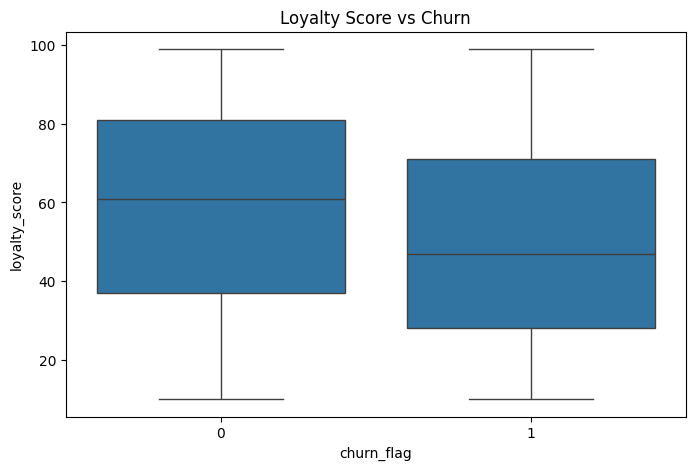

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="loyalty_score"
)

plt.title("Loyalty Score vs Churn")
plt.show()

#Churn vs Engagement


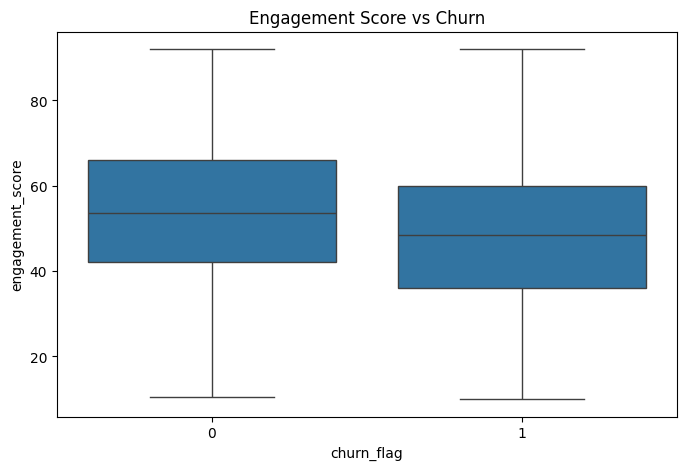

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="engagement_score"
)

plt.title("Engagement Score vs Churn")
plt.show()

#Churn by customer segment

In [ ]:
segment_churn = pd.crosstab(
    df["customer_segment"],
    df["churn_flag"],
    normalize="index"
) * 100

segment_churn.round(2)

churn_flag,0,1
customer_segment,,
Loyal,54.07,45.93
New,53.68,46.32
Returning,54.02,45.98
VIP,53.33,46.67


##Coustomer segment visualization

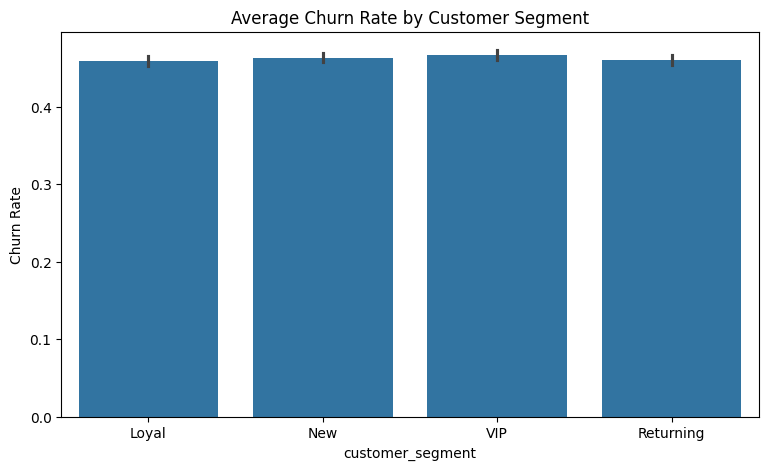

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="customer_segment",
    y="churn_flag"
)

plt.title("Average Churn Rate by Customer Segment")
plt.ylabel("Churn Rate")

plt.show()

##Churn by preferred channel

In [ ]:
channel_churn = pd.crosstab(
    df["preferred_channel"],
    df["churn_flag"],
    normalize="index"
) * 100

channel_churn.round(2)

churn_flag,0,1
preferred_channel,,
In-Store,53.74,46.26
Mobile App,54.25,45.75
Online,53.34,46.66


##Channel visualization

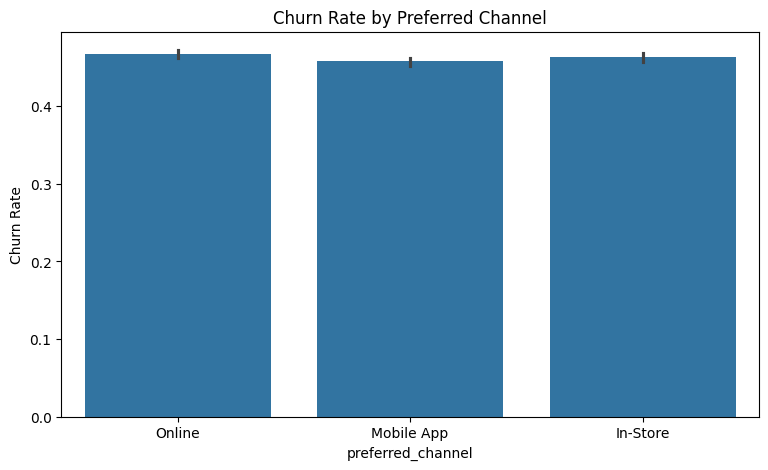

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="preferred_channel",
    y="churn_flag"
)

plt.title("Churn Rate by Preferred Channel")
plt.ylabel("Churn Rate")

plt.show()

#Region visualiation

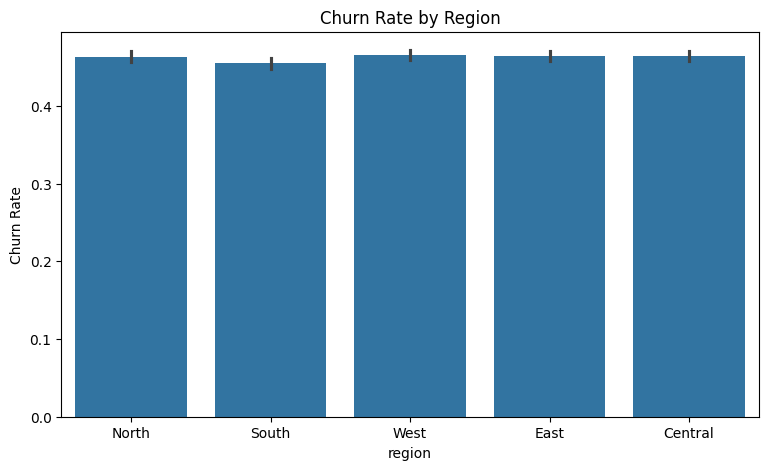

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="region",
    y="churn_flag"
)

plt.title("Churn Rate by Region")
plt.ylabel("Churn Rate")

plt.show()

##Correlation matrix

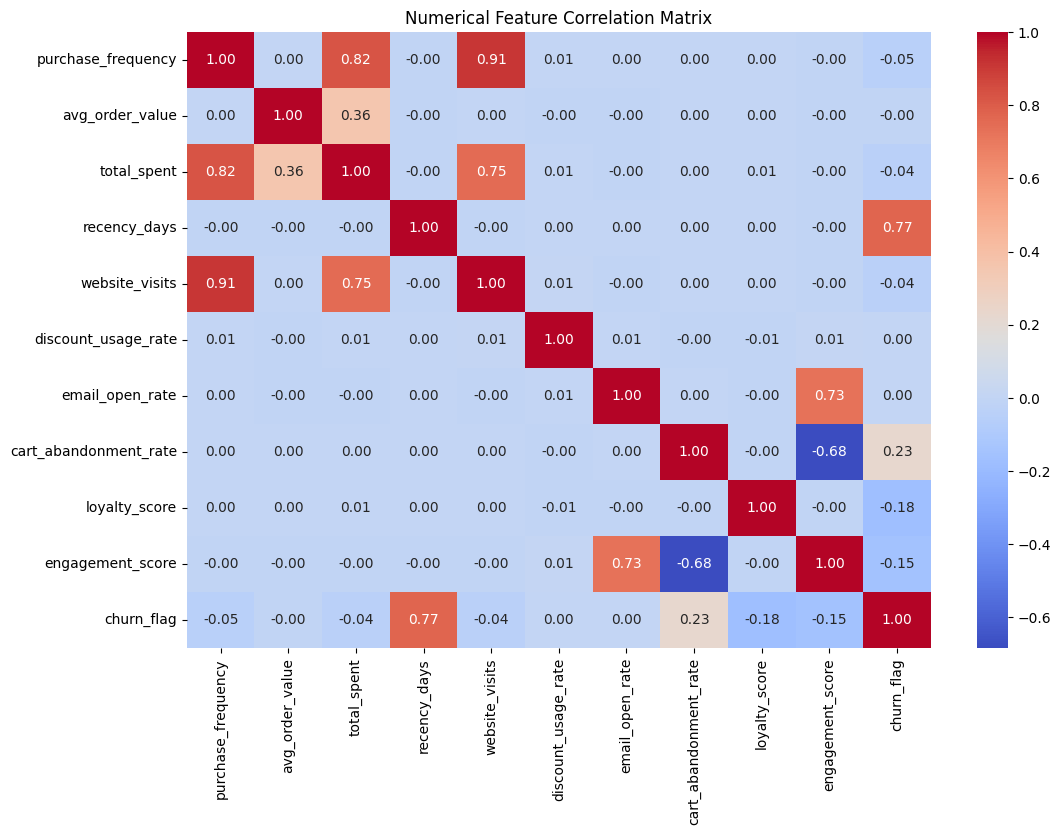

In [ ]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Numerical Feature Correlation Matrix")

plt.show()

#Churn Characteristics

##Numerical comparison by churn

In [ ]:
churn_comparison = df.groupby(
    "churn_flag"
)[numerical_columns].mean().T

churn_comparison

churn_flag,0,1
purchase_frequency,12.466342,11.029595
avg_order_value,210.145141,209.192351
total_spent,2692.556727,2370.936140
recency_days,107.301993,270.504110
website_visits,61.745649,54.776804
discount_usage_rate,0.425870,0.426681
email_open_rate,0.473958,0.475171
cart_abandonment_rate,0.402234,0.507693
loyalty_score,58.834926,49.709588
engagement_score,53.586209,48.373875


#Data Preparation

#Creating modeling dataset

In [ ]:
model_df = df.copy()

# Remove customer identifier
# Remove churn_risk because it causes target leakage
model_df = model_df.drop(
    columns=[
        "customer_id",
        "churn_risk"
    ]
)

print("Original shape:", df.shape)
print("Modeling shape:", model_df.shape)

Original shape: (100000, 18)
Modeling shape: (100000, 16)


#Seperate X and y

In [ ]:
X = model_df.drop(
    columns=["churn_flag"]
)

y = model_df["churn_flag"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 15)
y shape: (100000,)


##Identify feature types

In [ ]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel']

Numerical features:
['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']


#Train  & Split

##split dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 80000
Testing samples : 20000


#Preprocessing Pipeline

##Create preporcessing pipeline

In [ ]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


#Five ML Models
1. Logistic Regression
2. Random Forest
3. Extra Trees
4. Gradient Boosting
5. XGBoost


In [ ]:
!pip -q install xgboost

In [ ]:
from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


##Define Models

##Five models

In [ ]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("Number of models:", len(models))

Number of models: 5


#Create ML Pipelines

In [ ]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

print("All model pipelines created.")

All model pipelines created.


#Train five Models

In [ ]:
trained_models = {}

for name, pipeline in pipelines.items():

    print(f"\nTraining: {name}")

    pipeline.fit(
        X_train,
        y_train
    )

    trained_models[name] = pipeline

    print(f"{name} completed.")


Training: Logistic Regression
Logistic Regression completed.

Training: Random Forest
Random Forest completed.

Training: Extra Trees
Extra Trees completed.

Training: Gradient Boosting
Gradient Boosting completed.

Training: XGBoost
XGBoost completed.


#Model Evaluation

##Evaluation function

In [ ]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions
        ),

        "Recall": recall_score(
            y_test,
            predictions
        ),

        "F1 Score": f1_score(
            y_test,
            predictions
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }

##Evaluate all five

In [ ]:
results = []

for name, model in trained_models.items():

    metrics = evaluate_model(
        model,
        X_test,
        y_test
    )

    metrics["Model"] = name

    results.append(metrics)

results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
]

results_df.sort_values(
    "ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.94590,0.941864,0.941049,0.941457,0.990379
4,XGBoost,0.94390,0.939224,0.939427,0.939325,0.989858
3,Gradient Boosting,0.94500,0.940794,0.940184,0.940489,0.989848
1,Random Forest,0.94205,0.937933,0.936614,0.937273,0.988313
2,Extra Trees,0.93885,0.938456,0.928610,0.933507,0.988191


#Visual Model Comparison

##Compare models

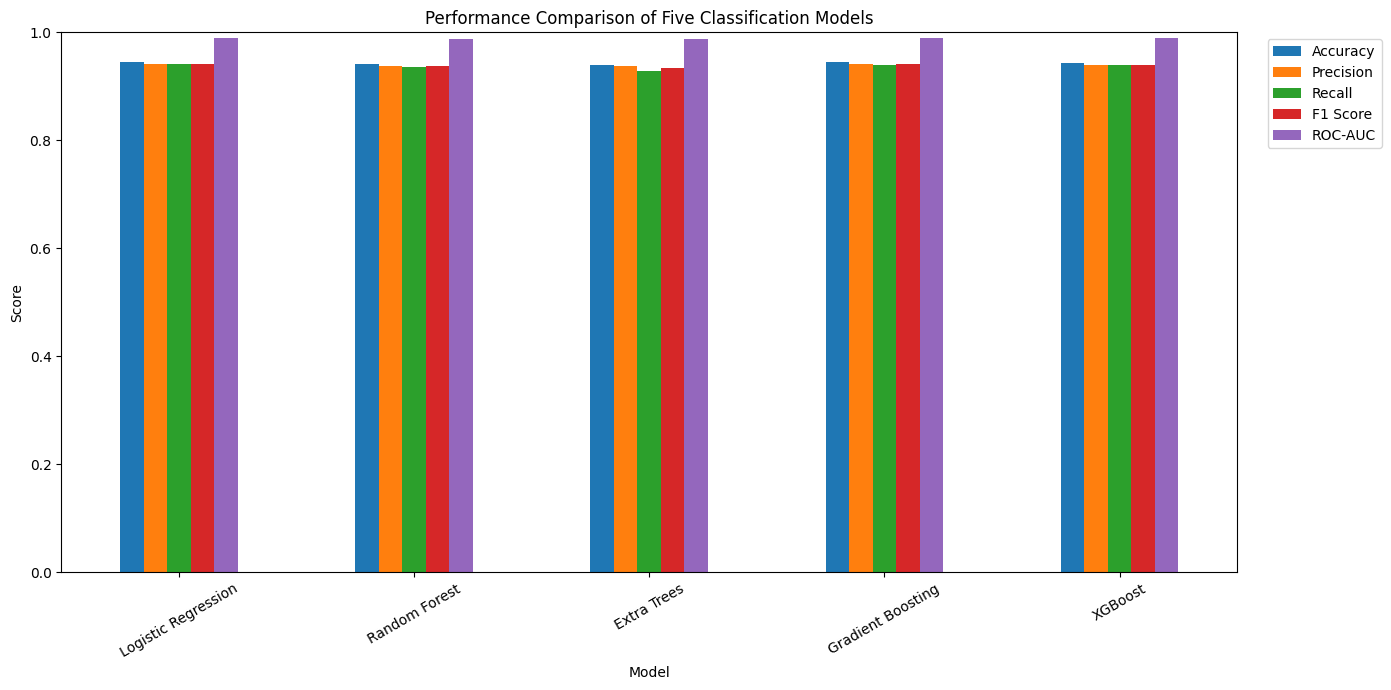

In [ ]:
comparison = results_df.set_index("Model")

comparison.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Performance Comparison of Five Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=30)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#F1 Score comparison

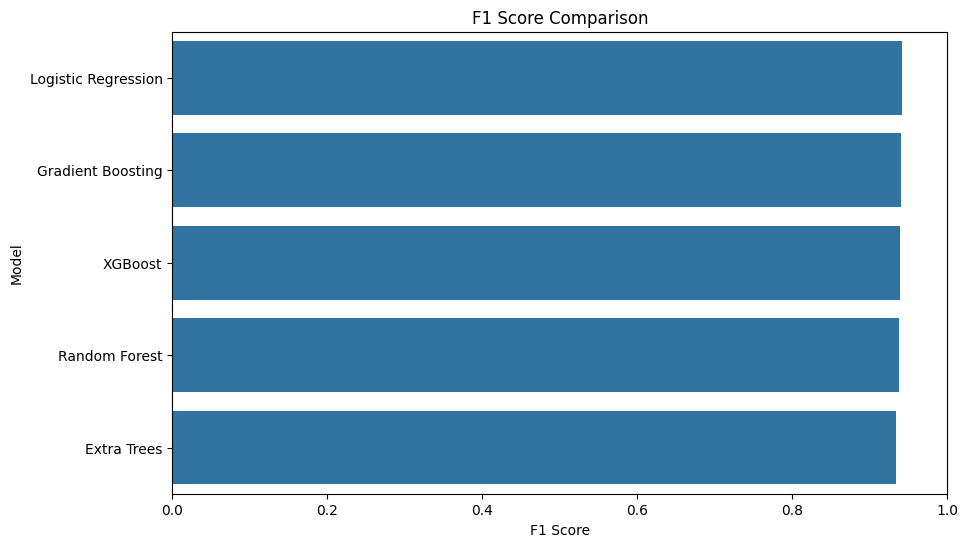

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df.sort_values(
        "F1 Score",
        ascending=False
    ),
    x="F1 Score",
    y="Model"
)

plt.title("F1 Score Comparison")
plt.xlim(0, 1)

plt.show()

#ROC AUC Comparison

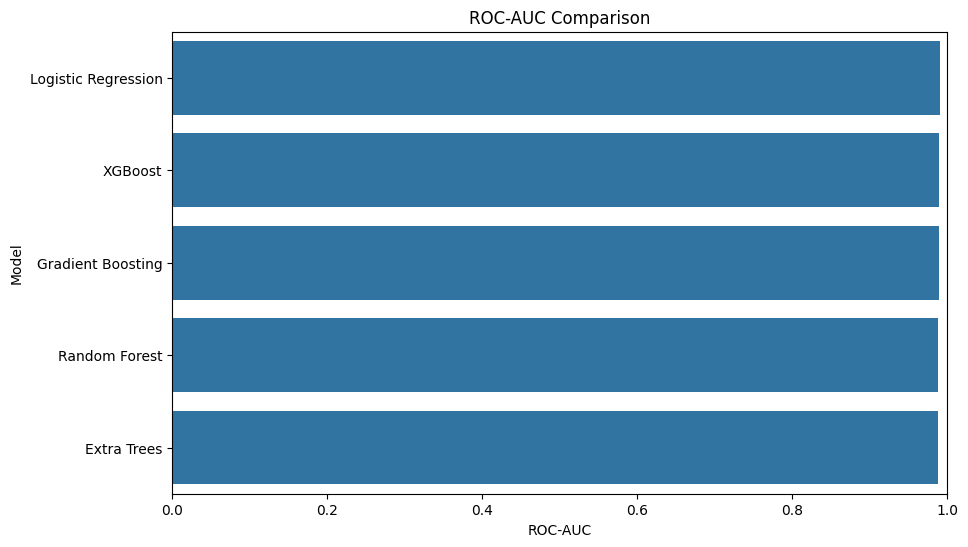

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df.sort_values(
        "ROC-AUC",
        ascending=False
    ),
    x="ROC-AUC",
    y="Model"
)

plt.title("ROC-AUC Comparison")
plt.xlim(0, 1)

plt.show()

#Cross Validation

5 flod cross validation

In [54]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, pipeline in pipelines.items():

    print(f"Cross-validating: {name}")

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

cv_df.sort_values(
    "CV ROC-AUC",
    ascending=False
)

Cross-validating: Logistic Regression
Cross-validating: Random Forest
Cross-validating: Extra Trees
Cross-validating: Gradient Boosting
Cross-validating: XGBoost


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.94438,0.939769,0.939923,0.939843,0.990262
3,Gradient Boosting,0.94341,0.938500,0.939122,0.938808,0.989682
4,XGBoost,0.94258,0.937272,0.938603,0.937934,0.989645
1,Random Forest,0.94052,0.936391,0.934839,0.935609,0.988124
2,Extra Trees,0.93887,0.937743,0.929474,0.933583,0.987985


#Final Model Selection

In [55]:
final_comparison = results_df.merge(
    cv_df,
    on="Model"
)

final_comparison.sort_values(
    "CV ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.94590,0.941864,0.941049,0.941457,0.990379,0.94438,0.939769,0.939923,0.939843,0.990262
3,Gradient Boosting,0.94500,0.940794,0.940184,0.940489,0.989848,0.94341,0.938500,0.939122,0.938808,0.989682
4,XGBoost,0.94390,0.939224,0.939427,0.939325,0.989858,0.94258,0.937272,0.938603,0.937934,0.989645
1,Random Forest,0.94205,0.937933,0.936614,0.937273,0.988313,0.94052,0.936391,0.934839,0.935609,0.988124
2,Extra Trees,0.93885,0.938456,0.928610,0.933507,0.988191,0.93887,0.937743,0.929474,0.933583,0.987985


##Select best model

In [56]:
best_model_name = (
    final_comparison
    .sort_values(
        "CV ROC-AUC",
        ascending=False
    )
    .iloc[0]["Model"]
)

best_model = trained_models[
    best_model_name
]

print("Best Model:")
print(best_model_name)

Best Model:
Logistic Regression


#Confution Metrix

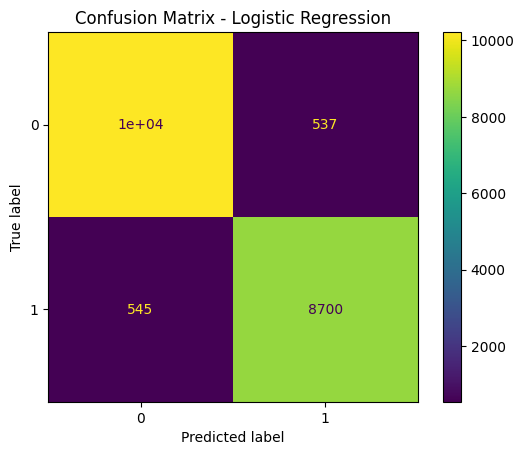

In [57]:
y_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.show()

#Classification Report

In [58]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Churn",
            "Churn"
        ]
    )
)

              precision    recall  f1-score   support

    No Churn       0.95      0.95      0.95     10755
       Churn       0.94      0.94      0.94      9245

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000



#ROC curves for all 5 models

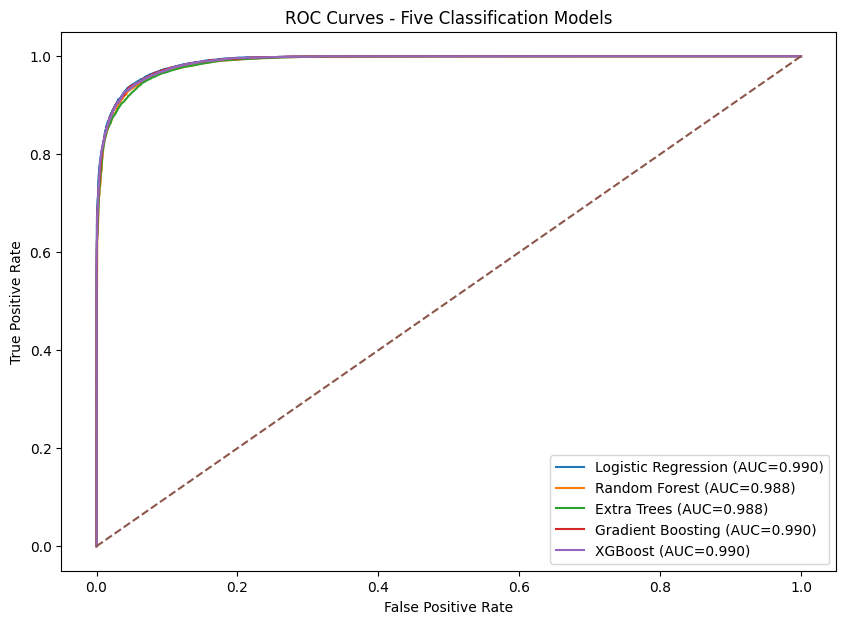

In [59]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    from sklearn.metrics import roc_curve

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves - Five Classification Models")

plt.legend()

plt.show()

#Feature Importance

In [60]:
model_step = best_model.named_steps["model"]

if hasattr(model_step, "feature_importances_"):

    importances = model_step.feature_importances_

    print("Feature importance available.")

else:

    print(
        "The selected model does not provide "
        "feature_importances_ directly."
    )

The selected model does not provide feature_importances_ directly.


##Get feature names

In [61]:
preprocessor_fitted = (
    best_model
    .named_steps["preprocessor"]
)

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

print("Number of processed features:")
print(len(feature_names))

Number of processed features:
30


##Feature importance table

In [62]:
if hasattr(model_step, "feature_importances_"):

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    importance_df.head(20)

#Business Insights

##Automatically identify high churn groups

In [63]:
def churn_rate_table(data, column):

    result = (
        data.groupby(column)["churn_flag"]
        .agg(
            Customers="count",
            Churn_Rate="mean"
        )
        .sort_values(
            "Churn_Rate",
            ascending=False
        )
    )

    result["Churn_Rate"] *= 100

    return result.round(2)

##Segment insights

In [64]:
churn_rate_table(
    df,
    "customer_segment"
)

,Customers,Churn_Rate
customer_segment,,
VIP,24906,46.67
New,25113,46.32
Returning,25106,45.98
Loyal,24875,45.93


##Channel insights


In [65]:
churn_rate_table(
    df,
    "preferred_channel"
)

,Customers,Churn_Rate
preferred_channel,,
Online,33430,46.66
In-Store,33303,46.26
Mobile App,33267,45.75


##Region insights

In [66]:
churn_rate_table(
    df,
    "region"
)

,Customers,Churn_Rate
region,,
West,20039,46.50
Central,20012,46.45
East,20240,46.36
North,20035,46.33
South,19674,45.46


##Age insights

In [67]:
churn_rate_table(
    df,
    "age_group"
)

,Customers,Churn_Rate
age_group,,
55+,19882,46.51
35-44,20109,46.37
18-24,19987,46.24
45-54,20093,46.11
25-34,19929,45.89


#High Risk Customer Analysis


In [68]:
test_results = X_test.copy()

test_results["actual_churn"] = y_test.values
test_results["predicted_churn"] = y_pred

test_results.head()

,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,actual_churn,predicted_churn
25119,25-34,Male,West,Loyal,Online,12,106.85,1462.91,131,67,0.23,0.24,0.57,14,33.5,1,1
84952,45-54,Male,East,Returning,Online,35,35.79,1440.11,242,240,0.14,0.10,0.36,80,37.0,0,0
37029,18-24,Female,West,Loyal,Mobile App,20,201.71,3737.23,60,153,0.73,0.74,0.25,22,74.5,0,0
32013,35-44,Male,East,New,In-Store,20,250.27,5417.70,109,65,0.52,0.06,0.11,40,47.5,0,0
86566,18-24,Male,North,VIP,In-Store,5,318.85,1450.92,18,13,0.51,0.70,0.17,59,76.5,0,0


#Save Processed Data

In [69]:
processed_data = model_df.copy()

processed_data.to_csv(
    "processed_customer_churn.csv",
    index=False
)

print(
    "Processed dataset saved successfully."
)

Processed dataset saved successfully.


#Save Best Model

In [70]:
joblib.dump(
    best_model,
    "best_customer_churn_model.pkl"
)

print(
    f"Saved model: {best_model_name}"
)

Saved model: Logistic Regression


#Save model information

In [71]:
model_information = {
    "model_name": best_model_name,
    "target": "churn_flag",
    "excluded_features": [
        "customer_id",
        "churn_risk"
    ],
    "training_rows": len(X_train),
    "testing_rows": len(X_test),
    "selection_metric": "CV ROC-AUC"
}

model_information

{'model_name': 'Logistic Regression',
 'target': 'churn_flag',
 'excluded_features': ['customer_id', 'churn_risk'],
 'training_rows': 80000,
 'testing_rows': 20000,
 'selection_metric': 'CV ROC-AUC'}

#Deployment -Ready Prediction Function

In [72]:
def predict_customer_churn(
    customer_data,
    model=best_model
):

    prediction = model.predict(
        customer_data
    )

    probability = model.predict_proba(
        customer_data
    )[:, 1]

    result = customer_data.copy()

    result["predicted_churn"] = prediction
    result["churn_probability"] = probability

    return result

#Test One customer

In [73]:
sample_customer = X_test.iloc[[0]]

prediction_result = predict_customer_churn(
    sample_customer
)

prediction_result

,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,predicted_churn,churn_probability
25119,25-34,Male,West,Loyal,Online,12,106.85,1462.91,131,67,0.23,0.24,0.57,14,33.5,1,0.616803


#Test Multiple customers

In [74]:
sample_customers = X_test.head(10)

predictions = predict_customer_churn(
    sample_customers
)

predictions[
    [
        "predicted_churn",
        "churn_probability"
    ]
]

,predicted_churn,churn_probability
25119,1,6.168026e-01
84952,0,2.415370e-01
37029,0,6.271442e-05
32013,0,6.230200e-05
86566,0,7.849671e-08
89333,1,9.965432e-01
97058,1,9.920109e-01
17984,1,9.863789e-01
92561,0,6.334697e-04
71328,0,3.747535e-05


#Download Model

In [75]:
from google.colab import files

files.download(
    "best_customer_churn_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Download preprocessed data

In [76]:
files.download(
    "processed_customer_churn.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>